# 从一个 Block 到 OpenMythos：循环 Transformer 入门

循环 Transformer 的想法简单得几乎有点冒犯：拿一个 Transformer block，重复用几次，
让同一组权重多干一点活。参数量一个都没加，模型却变"深"了。

这份 notebook 用六个小步骤把这个想法从零搭起来，最后读一遍
[OpenMythos](https://github.com/kyegomez/OpenMythos) 的源码——一个开放实现的递归深度
Transformer。读完之后，你会亲手训练一个循环模型，量出"多循环"到底买到了什么，看到它在什么
地方停止起作用，并认出那些让这个想法在真实训练中活下来的工程细节。

**你需要什么：** 一台笔记本。每个 cell 都在 CPU 上几秒钟跑完，任务是合成的，唯一依赖是 PyTorch。

**怎么读：** 代码刻意写得极小（总共约 150 行，不用任何框架）。先读文字，再运行，然后看图。
每章末尾都会指向配套论文列表
[Awesome-Loop-Transformers](https://github.com/Mrkkew/Awesome-Loop-Transformers)
里的相应分组，方便你从玩具走向文献。

| 章节 | 回答的问题 |
| --- | --- |
| 0 | 这个想法长什么形状？ |
| 1 | 固定深度的 Transformer 到底会*输*在哪？ |
| 2 | 复用同一个 block 之后，什么变了？ |
| 3 | 一个能训练的循环，需要哪几件东西？ |
| 4 | 循环什么时候该停？ |
| 5 | OpenMythos 怎么把它们组装起来？ |
| 6 | 接下来读什么 |

*正文与代码：CC BY 4.0，与本仓库一致。OpenMythos 源码是 MIT，这里只 import，不复制。*

In [1]:
%matplotlib inline
import math, time
from pathlib import Path

import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

torch.manual_seed(0)
torch.set_num_threads(4)

INK, CYAN, LIME, VIOLET, MUTED, GRID = (
    "#0B1020", "#1F7A99", "#6F9E1F", "#5B4BD6", "#6B7385", "#E7EAF3",
)
plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 160, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.9,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
    "lines.linewidth": 2.0,
})
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

def save(fig, name):
    '''Save a copy for the README; harmless if the directory is read-only.'''
    try:
        fig.savefig(FIGDIR / name, bbox_inches="tight")
    except OSError:
        pass

P, D = 7, 64                     # residue modulus, model width

class Block(nn.Module):
    '''Pre-norm Transformer block: causal self-attention + MLP.'''
    def __init__(self, d, heads=4):
        super().__init__()
        self.heads = heads
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x):
        b, n, d = x.shape
        q, k, v = self.qkv(self.n1(x)).split(d, dim=2)
        q, k, v = (t.view(b, n, self.heads, d // self.heads).transpose(1, 2) for t in (q, k, v))
        att = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        x = x + self.proj(att.transpose(1, 2).reshape(b, n, d))
        return x + self.mlp(self.n2(x))

print("torch", torch.__version__, "| device:", "cuda" if torch.cuda.is_available() else "cpu")
print(f"one block: {sum(p.numel() for p in Block(D).parameters()):,} parameters")

torch 2.15.0 | device: cpu
one block: 49,984 parameters


## 0. 这个想法的形状

三个部分，而不是一个：

- **Prelude（前奏）** —— 一个普通 Transformer 栈，只跑*一次*，把 token 变成隐状态 `e`。
- **Recurrent block（循环块）** —— 一个小栈，被应用 `T` 次。第 `t` 次读入上一状态 `h_t` 和注入的
  输入 `e`，写出 `h_{t+1}`。每次循环共享同一组权重。
- **Coda（尾声）** —— 一个普通栈，只跑*一次*，把最终状态变成 logits。

参数量由"块"决定，而不由 `T` 决定。这就是全部的交易：用*推理*算力（以及一些训练不稳定性）
去换*深度*。

下面的输出画出数据流。价格留到第 2 章再算——那时两个模型都已经存在，比较的是实测值而不是估算。

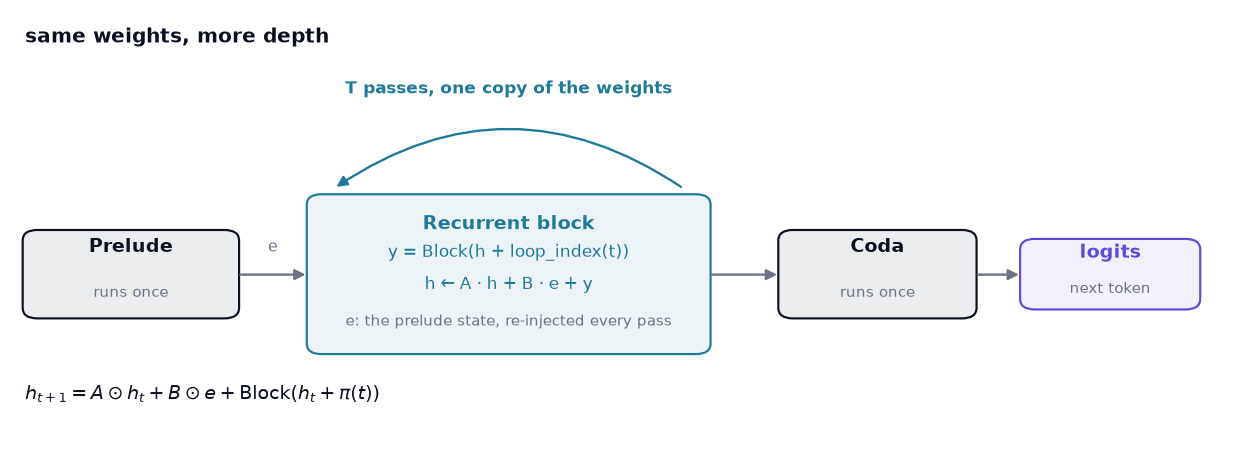

In [2]:
def diagram():
    fig, ax = plt.subplots(figsize=(9.6, 3.7))
    ax.set_axis_off(); ax.set_xlim(0, 10); ax.set_ylim(0, 4.95)

    def box(x, y, w, h, label, sub, color):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                    linewidth=1.2, edgecolor=color, facecolor=color + "14"))
        ax.text(x + w / 2, y + h * 0.82, label, ha="center", va="center",
                fontsize=10.5, fontweight="bold", color=color)
        if sub:
            ax.text(x + w / 2, y + h * 0.28, sub, ha="center", va="center",
                    fontsize=8.5, color=MUTED)

    def arrow(x0, y0, x1, y1, color=MUTED, rad=0.0):
        ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=12,
                                     linewidth=1.3, color=color,
                                     connectionstyle=f"arc3,rad={rad}"))

    box(0.10, 1.55, 1.75, 0.95, "Prelude", "runs once", INK)
    box(2.45, 1.15, 3.30, 1.75, "Recurrent block", "", CYAN)
    box(6.35, 1.55, 1.60, 0.95, "Coda", "runs once", INK)
    box(8.35, 1.65, 1.45, 0.75, "logits", "next token", VIOLET)

    # three readable lines beat one crowded caption
    ax.text(4.10, 2.22, "y = Block(h + loop_index(t))", ha="center", fontsize=9.2, color=CYAN)
    ax.text(4.10, 1.86, "h ← A · h + B · e + y", ha="center", fontsize=9.2, color=CYAN)
    ax.text(4.10, 1.45, "e: the prelude state, re-injected every pass", ha="center",
            fontsize=8.2, color=MUTED)

    arrow(1.85, 2.02, 2.45, 2.02)
    ax.text(2.15, 2.28, "e", ha="center", fontsize=8.6, color=MUTED)
    arrow(5.75, 2.02, 6.35, 2.02)
    arrow(7.95, 2.02, 8.35, 2.02)

    # the recurrence itself: an arc leaves the block on the right, returns on the left
    arrow(5.55, 2.98, 2.65, 2.98, color=CYAN, rad=0.34)
    ax.text(4.10, 4.05, "T passes, one copy of the weights", ha="center",
            fontsize=9.4, color=CYAN, fontweight="bold")

    ax.text(0.10, 4.62, "same weights, more depth", fontsize=11, fontweight="bold", color=INK)
    ax.text(0.10, 0.62,
            r"$h_{t+1}=A\odot h_t+B\odot e+\mathrm{Block}(h_t+\pi(t))$",
            fontsize=10.5, color=INK)
    fig.tight_layout(); save(fig, "01-architecture.png"); plt.show()

diagram()

pass  # chapter 2 prices this model, once the looped version exists

## 1. 一个"深度就是全部难点"的任务

模糊的任务只会得到模糊的曲线。所以我们需要一个难度**恰好**等于"顺序步数"的任务。取模 7 加法：

> 读入 `a_1 … a_k`，输出 `(a_1 + … + a_k) mod 7`

一次前向能靠模式匹配学会 `a_1 + a_2`，但学不会 `a_1 + … + a_8`：没有任何单次 attention 查表
能组合八次加法，因为第 `i` 步的结果是第 `i+1` 步的*输入*。这是我们能造出的最小、最诚实的深度
测试：`k` 是一个可以拧大的旋钮，标签是精确的。

下面给出模型、训练器，以及一个固定深度基线（四个互不共享的 block）：在 `k ≤ 4` 上训练，
一直评估到 `k = 8`。注意那个断崖。

In [3]:
def make_batch(bs, k, p=P):
    a = torch.randint(0, p, (bs, k))
    return a, a.sum(1) % p          # tokens, exact target

class FixedDepth(nn.Module):
    '''The control: one block per layer, no reuse. Depth is baked into the weights.'''
    def __init__(self, d=D, depth=4):
        super().__init__()
        self.embed, self.pos = nn.Embedding(P, d), nn.Embedding(32, d)
        self.blocks = nn.ModuleList([Block(d) for _ in range(depth)])
        self.norm, self.head = nn.LayerNorm(d), nn.Linear(d, P)

    def forward(self, a, loops=None):
        x = self.embed(a) + self.pos(torch.arange(a.shape[1]))
        for blk in self.blocks:
            x = blk(x)
        return self.head(self.norm(x[:, -1]))

def train(model, steps=1200, k_max=4, lr=3e-3, bs=64):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    for _ in range(steps):
        k = int(torch.randint(1, k_max + 1, (1,)))
        a, y = make_batch(bs, k)
        loss = F.cross_entropy(model(a, k), y)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
    return loss.item()

@torch.no_grad()
def accuracy(model, k, loops=None, bs=512):
    # fixed evaluation batch per k, so the table, the heatmap and the prose agree
    g = torch.Generator().manual_seed(1234)
    a = torch.randint(0, P, (bs, k), generator=g)
    y = a.sum(1) % P
    return (model(a, loops).argmax(-1) == y).float().mean().item()

torch.manual_seed(0)
t0 = time.time()
baseline = FixedDepth(depth=4)
final_loss = train(baseline)
print(f"trained in {time.time() - t0:.1f}s, final loss {final_loss:.3f}, "
      f"{sum(p.numel() for p in baseline.parameters()):,} params")
print("k :", "  ".join(f"{k}" for k in range(1, 9)))
print("acc:", "  ".join(f"{accuracy(baseline, k):.2f}" for k in range(1, 9)))

trained in 3.8s, final loss 0.001, 203,015 params
k : 1  2  3  4  5  6  7  8
acc: 1.00  1.00  1.00  0.94  0.12  0.14  0.14  0.14


基线模型把 `k ≤ 3` 全解对了，`k = 4` 也几乎全对（0.94），然后立刻崩掉：四个 block，就只能做四步组合，
不加新权重就加不出第五步。注意它*没有*做的事——它不会平缓退化。

把这个模型留住，它是后面所有对比的对照组。它同时带着一个诚实的提醒：循环模型在 `k = 5` 上
会撞到同一堵墙，因为它同样只在 `k ≤ 4` 上训练过。循环改变的不是模型能泛化多远，而是一步的
*价格*——是新增一个 block，还是在已有的 block 上多跑一次。

## 2. 复用这个块

现在做定义整个家族的那个改动：只保留**两个** block，然后应用 `T` 次。有两样东西让递归真正成立：

- **输入注入** —— 每一次循环都把 `e` 加进去。没有它，模型只能从一个不断漂移的状态里"回忆"
  题目；有了它，每次循环都能重新读到输入，同时带着已经算出的部分结果。
- **状态衰减** —— 更新前先把 `h` 乘以一个对角矩阵 `A`。这就是 OpenMythos 从 Parcae 一系工作
  继承来的 LTI（线性时不变）注入；此刻你只要把它读成"每个通道一个可学习的遗忘门"。

一个关键的训练细节：我们用 `loops = k` 训练。也就是说告诉模型"这题需要几步组合"，这恰好是论文
列表里 **adaptive compute**（自适应计算）那一栏讨论的设定。到推理时循环数变成自由变量，下面的
表格就来扫它。

In [4]:
class LoRA(nn.Module):
    '''Low-rank update: per-pass specialisation for a few extra parameters.'''
    def __init__(self, d, rank):
        super().__init__()
        self.down, self.up = nn.Linear(d, rank, bias=False), nn.Linear(rank, d, bias=False)
        nn.init.zeros_(self.up.weight)

    def forward(self, x):
        return self.up(self.down(x))

class Looped(nn.Module):
    def __init__(self, d=D, depth=2, loops=4, loop_index=True, lora_rank=0):
        super().__init__()
        self.embed, self.pos = nn.Embedding(P, d), nn.Embedding(32, d)
        self.loop_index = nn.Embedding(32, d) if loop_index else None
        self.prelude = nn.ModuleList([Block(d)])
        self.core = nn.ModuleList([Block(d) for _ in range(depth)])
        self.coda = nn.ModuleList([Block(d)])
        self.norm, self.head = nn.LayerNorm(d), nn.Linear(d, P)
        self.lora = nn.ModuleList([LoRA(d, lora_rank) for _ in range(32)]) if lora_rank else None
        # LTI injection, confined to (0, 1) for any parameter value.
        # Formula as in OpenMythos LTIInjection.get_A() (MIT, kyegomez/OpenMythos).
        self.log_dt, self.log_A = nn.Parameter(torch.zeros(d)), nn.Parameter(torch.zeros(d))
        self.B = nn.Parameter(torch.ones(d))
        self.loops = loops

    @property
    def A(self):
        return torch.exp(-torch.exp((self.log_dt + self.log_A).clamp(-20, 20)))

    def forward(self, a, loops=None):
        loops = self.loops if loops is None else loops
        x = self.embed(a) + self.pos(torch.arange(a.shape[1]))
        for blk in self.prelude:
            x = blk(x)
        e, h = x, torch.zeros_like(x)
        for t in range(loops):
            y = h if self.loop_index is None else h + self.loop_index(torch.tensor(t))
            for blk in self.core:
                y = blk(y)
            if self.lora is not None:
                y = y + self.lora[t](y)
            h = self.A * h + self.B * e + y
        for blk in self.coda:
            h = blk(h)
        return self.head(self.norm(h[:, -1]))

torch.manual_seed(0)
t0 = time.time()
looped = Looped(loops=4)
train(looped, steps=1500)
print(f"trained in {time.time() - t0:.1f}s | {sum(p.numel() for p in looped.parameters()):,} params "
      f"| mean A = {looped.A.mean().item():.2f}")
print("k :", "  ".join(f"{k:4d}" for k in range(1, 7)))
for T in (1, 2, 3, 4, 5, 6):
    print(f"T={T}:", "  ".join(f"{accuracy(looped, k, T):.2f}" for k in range(1, 7)))

trained in 6.5s | 205,255 params | mean A = 0.29
k :    1     2     3     4     5     6
T=1: 1.00  0.76  0.50  0.23  0.12  0.16
T=2: 1.00  1.00  0.98  0.61  0.15  0.13
T=3: 0.43  0.98  1.00  0.93  0.17  0.14
T=4: 0.15  0.98  1.00  0.98  0.16  0.13
T=5: 0.15  0.90  0.96  0.96  0.15  0.15
T=6: 0.15  0.81  0.92  0.90  0.15  0.13


对角线就是答案。准确率大体跟着 `min(T, k)` 走——超过步数的循环买不到东西，而不足时它是
*温和地*退化，不是断崖：只跑一次时
`k = 2` 已经能到 0.76、`k = 4` 只剩 0.23；两次把 `k = 2` 送到 1.00，三次把 `k = 3` 送到 1.00，
四次把 `k = 4` 送到 0.98。而超过所需次数之后，曲线是*往下弯*的，不是持平——对一道已经做对的题
继续循环不是免费的，它只是又给了一次破坏状态的机会。

同一张表里还有两个诚实的注脚：

- **`T < k` 是"软失败"。** 想得不够不等于想得少一点，它是另一个答案。
- **没见过的 `k` 不会迁移。** 在 `k ≤ 4` 上训练、在 `k = 6` 上评估，无论 `T` 取多少都在瞎猜水平。
  复用权重买到的是*训练范围内*的深度；超出范围的外推是一个开放问题，不是免费午餐。

下图把这条对角线画出来，并把固定深度基线放进同一坐标系。

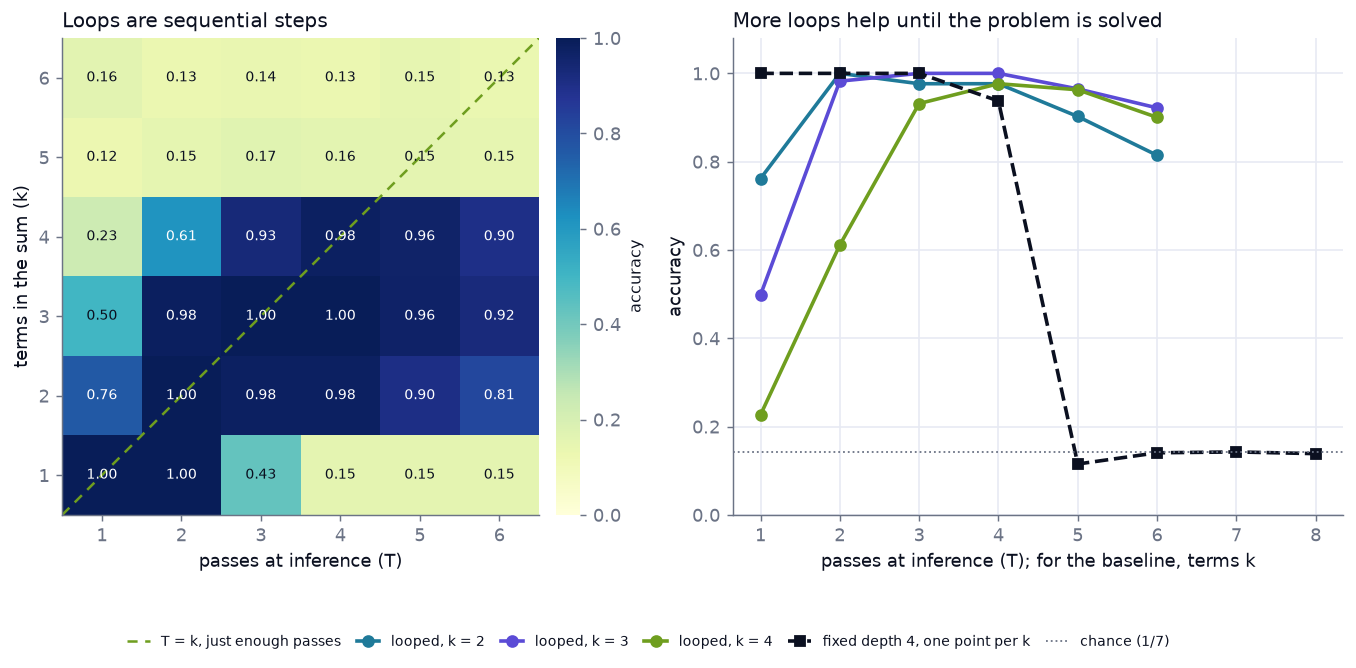

In [5]:
ks = list(range(1, 7))
grid = [[accuracy(looped, k, T) for T in range(1, 7)] for k in ks]

fig, axes = plt.subplots(1, 2, figsize=(11.0, 5.0), gridspec_kw={"width_ratios": [1, 1.05]})
ax = axes[0]
im = ax.imshow(grid, cmap="YlGnBu", vmin=0, vmax=1, origin="lower")
ax.set_xticks(range(6), range(1, 7)); ax.set_yticks(range(6), range(1, 7))
ax.set_xlabel("passes at inference (T)"); ax.set_ylabel("terms in the sum (k)")
ax.set_title("Loops are sequential steps", loc="left"); ax.grid(False)
for i, row in enumerate(grid):
    for j, v in enumerate(row):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if v > 0.6 else INK)
ax.plot([-0.5, 5.5], [-0.5, 5.5], color=LIME, linewidth=1.4, linestyle=(0, (4, 3)),
        label="T = k, just enough passes")
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cbar.set_label("accuracy", fontsize=9); cbar.outline.set_visible(False)

ax = axes[1]
for k, color in zip((2, 3, 4), (CYAN, VIOLET, LIME)):
    ax.plot(range(1, 7), [accuracy(looped, k, T) for T in range(1, 7)], "o-",
            color=color, label=f"looped, k = {k}")
ax.plot(range(1, 9), [accuracy(baseline, k) for k in range(1, 9)], "s--", color=INK,
        label="fixed depth 4, one point per k")
ax.axhline(1 / P, color=MUTED, linewidth=1.0, linestyle=":", label=f"chance (1/{P})")
ax.set_xlabel("passes at inference (T); for the baseline, terms k")
ax.set_ylabel("accuracy")
ax.set_ylim(0, 1.08); ax.set_xticks(range(1, 9))
ax.set_title("More loops help until the problem is solved", loc="left")

# one legend for both panels, below the axis labels: keeping it out of the heatmap
# matters, every cell is already labelled
h1, l1 = axes[0].get_legend_handles_labels()
h2, l2 = axes[1].get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="lower center", bbox_to_anchor=(0.5, -0.03), ncol=6,
           frameon=False, fontsize=7.9, handlelength=1.6, columnspacing=1.1)
fig.tight_layout(rect=(0, 0.08, 1, 1)); save(fig, "03-depth-diagonal.png"); plt.show()

把右图读成一条预算线：`k = 2` 时两次循环就够，第六次是浪费；`k = 4` 时需要四次。虚线对照画在 `k` 轴上——固定深度的栈没有可变的 `T`：
它在训练过的地方极好，往后再走一步就无能为力。

> **延伸阅读。** "深度即算力"的框架、`min(T, k)` 的对角线、以及 underthinking 这个失败模式，正是
> [目录](https://github.com/Mrkkew/Awesome-Loop-Transformers#adaptive-compute)中
> *自适应计算* 这一栏的主题：深度组合（把深度当作候选答案来源）、固定视界的潜在推理（为什么
> 一直算到上限反而更差）、以及让新 token 跳过早期循环的 late-entry 方法。

在往下走之前，先给刚搭好的东西标价。循环模型有四个 block（一个 prelude、两个共享块、
一个 coda），再加上嵌入、loop index 和注入门——这个总数不随 `T` 改变。而对照组只能按栈的方式
为深度付费：多一步，就多一个 block。

一张图就是这笔交易：一条随深度上升的线，和一条不动的线。

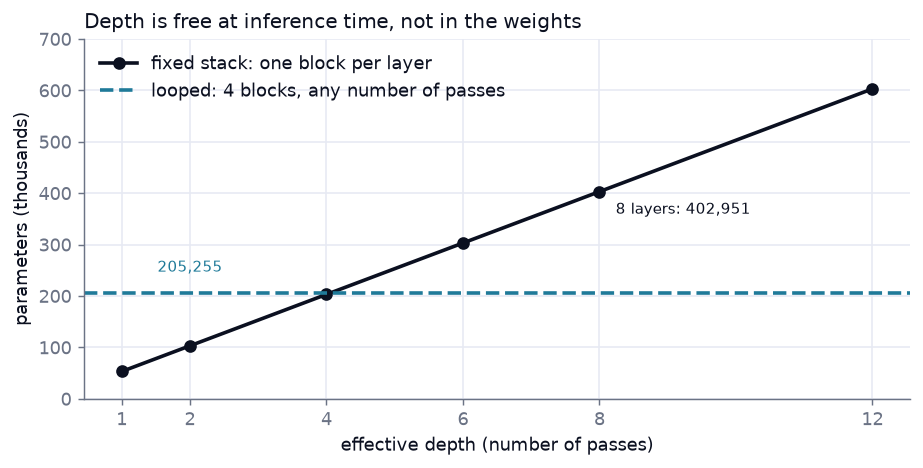

one block                 49,984
looped model              205,255   (independent of T)
  of which 4 x block      199,936
fixed stack, depth 8      402,951
ratio at depth 8          1.96x


In [6]:
def n_params(m):
    return sum(p.numel() for p in m.parameters())

depths = [1, 2, 4, 6, 8, 12]
fig, ax = plt.subplots(figsize=(7.2, 3.7))
ax.plot(depths, [n_params(FixedDepth(depth=d)) / 1e3 for d in depths], "o-",
        color=INK, label="fixed stack: one block per layer")
ax.axhline(n_params(looped) / 1e3, color=CYAN, linestyle="--",
           label="looped: 4 blocks, any number of passes")
ax.annotate(f"{n_params(looped):,}", xy=(2, n_params(looped) / 1e3), xytext=(0, 10),
            textcoords="offset points", ha="center", va="bottom", fontsize=8.2, color=CYAN)
ax.annotate(f"8 layers: {n_params(FixedDepth(depth=8)):,}", xy=(8, n_params(FixedDepth(depth=8)) / 1e3),
            xytext=(9, -6), textcoords="offset points", ha="left", va="top",
            fontsize=8.2, color=INK)
ax.set_xlabel("effective depth (number of passes)"); ax.set_ylabel("parameters (thousands)")
ax.set_title("Depth is free at inference time, not in the weights", loc="left")
ax.legend(loc="upper left"); ax.set_xticks(depths); ax.set_ylim(0, 700)
fig.tight_layout(); save(fig, "02-params-vs-depth.png"); plt.show()

print(f"one block                 {n_params(Block(D)):,}")
print(f"looped model              {n_params(looped):,}   (independent of T)")
print(f"  of which 4 x block      {4 * n_params(Block(D)):,}")
print(f"fixed stack, depth 8      {n_params(FixedDepth(depth=8)):,}")
print(f"ratio at depth 8          {n_params(FixedDepth(depth=8)) / n_params(looped):.2f}x")

## 3. 让循环可训练的三件东西

一个共享 block 的循环还不是一个好模型。要把玩具变成能在规模上训练的东西，需要三样配料，每一样都
对应一个具体的失败。

### 3.1 块必须知道自己走到第几步

共享块看到的是 `h_t`，但 `h_t` 里没有任何信息说明这是第 2 次还是第 7 次。加一个可学习的步数嵌入
（"loop index"，位置嵌入在深度方向上的对应物），同一组权重就能在不同深度上表现不同。OpenMythos
正是这么做的，而且比查表更省：`loop_index_embedding(h, t, loop_dim)` 是一个正弦编码（RoPE 在
深度方向上的对应物），它被*加*到 `h` 的前 `loop_dim = dim // 8` 个通道上，其余状态原样通过：

```python
h_loop = loop_index_embedding(h, t, self.loop_dim)   # h + sinusoidal bias
combined = self.norm(h_loop + e)
```

我们的玩具走另一条省钱的路：一个可学习的 `Embedding(32, d)` 加到整个状态上。两条路要点相同：
共享权重需要知道自己是第几步，而两者都只花几千个参数。

### 3.2 每次循环各自特化，但不解开权重绑定

如果希望每次循环略有不同，朴素做法是"一次循环一个块"——参数量立刻退回固定深度栈。便宜的做法是
每次循环挂一个低秩适配器：`rank` 就是价格。OpenMythos 用的正是 depth-wise LoRA
（`LoRAAdapter`，默认 `lora_rank=16`）。下面的表格给你刚训好的模型把三种方案的价钱标出来。

### 3.3 递归必须有界

这是杀死朴素实现的那个失败。`h_{t+1} = A h_t + …` 是一个线性递归：只要 `A` 的谱半径大于 1，
状态就随深度几何增长，梯度也是。OpenMythos 干脆取消了这个选择，用重参数化

```python
A = exp(-exp(log_dt + log_A))     # LTIInjection.get_A()，clamp 到 (-20, 20)
```

它对任意参数取值都落在 `(0, 1)`。稳定性不再是你调的超参数，而是参数化的性质。接下来两格在同一
初始条件下把差别画出来。

In [7]:
def price(d=D, depth=2, rank=4, passes=8):
    shared = Looped(d=d, depth=depth, loop_index=False)
    base = sum(p.numel() for p in shared.parameters())
    unrolled = base + depth * passes * sum(p.numel() for p in Block(d).parameters())
    lora = base + passes * (rank * d * 2)
    return base, unrolled, lora

base, unrolled, lora = price()
print(f"shared core + one block, 8 passes   {base:>10,}")
print(f"8 independent blocks (no tying)     {unrolled:>10,}   ({unrolled / base:.2f}x)")
print(f"shared core + LoRA(r=4) on 8 passes {lora:>10,}   ({lora / base:.2f}x)")
print(f"LoRA adds {lora - base:,} params for {8} passes = {((lora - base) / 8):,.0f} per pass")

shared core + one block, 8 passes      203,207
8 independent blocks (no tying)      1,002,951   (4.94x)
shared core + LoRA(r=4) on 8 passes    207,303   (1.02x)
LoRA adds 4,096 params for 8 passes = 512 per pass


很便宜，而且这正是"一个有八种行为的模型"和"八个模型"的区别。注意适配器是零初始化的
（`up.weight = 0`），所以它在第 0 步不会破坏任何已经训好的权重。

接下来是稳定性。下面两栏用同一份随机 `A` 把同一个递归跑 16 次：一次不加约束
（`A = exp(raw)`，无界），一次加约束。注意纵轴是对数刻度——无界状态不是"稍微大一点"。

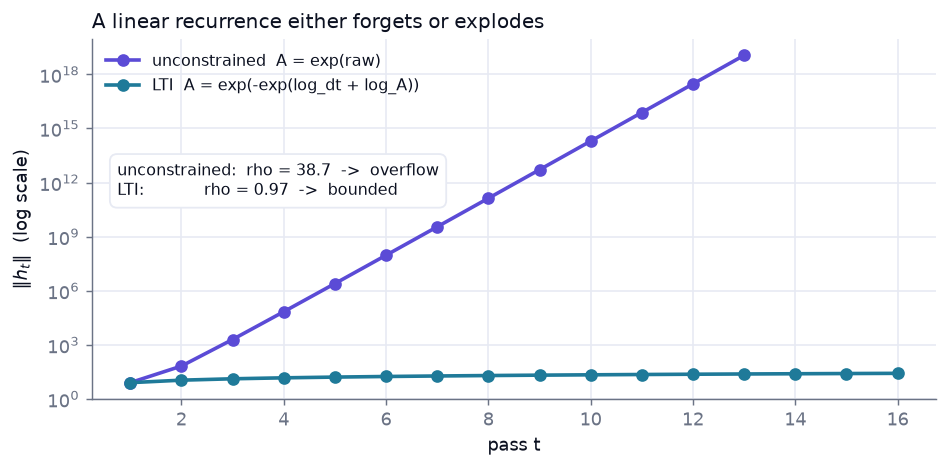

unconstrained: max |h| = inf after 16 passes
LTI:           max |h| = 26.3 after 16 passes
our trained model's mean rho = 0.29


In [8]:
torch.manual_seed(3)
raw = torch.randn(D) * 1.5        # the same draw feeds both branches
A_free = raw.exp()                                        # unbounded: exp(raw)
A_lti = torch.exp(-torch.exp(raw.clamp(-20, 20)))          # bounded: exp(-exp(raw))

def state_norm(A, passes=16, e=torch.ones(D)):
    h, norms = torch.zeros(D), []
    for _ in range(passes):
        h = A * h + e
        norms.append(h.norm().item())
    return norms

free, lti = state_norm(A_free), state_norm(A_lti)

fig, ax = plt.subplots(figsize=(7.4, 3.7))
ax.plot(range(1, 17), free, "o-", color=VIOLET, label="unconstrained  A = exp(raw)")
ax.plot(range(1, 17), lti, "o-", color=CYAN, label="LTI  A = exp(-exp(log_dt + log_A))")
ax.set_yscale("log"); ax.set_xlabel("pass t"); ax.set_ylabel(r"$\Vert h_t\Vert$  (log scale)")
ax.set_title("A linear recurrence either forgets or explodes", loc="left")
ax.legend(loc="upper left", fontsize=9)
ax.text(0.03, 0.66, f"unconstrained:  rho = {A_free.max():.1f}  ->  overflow\n"
                    f"LTI:            rho = {A_lti.max():.2f}  ->  bounded",
        transform=ax.transAxes, va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor=GRID))
fig.tight_layout(); save(fig, "04-stability.png"); plt.show()

print(f"unconstrained: max |h| = {max(free):.1f} after 16 passes")
print(f"LTI:           max |h| = {max(lti):.1f} after 16 passes")
print(f"our trained model's mean rho = {looped.A.mean().item():.2f}")

在训练好的模型里，这个门稳定在 `0.3` 左右：它*想要*在每次循环时忘掉大部分状态，重新读注入的
输入。这正是约束让它安全的行为——记忆很长的共享块是会炸的块，记忆很短的共享块才是能被循环的块。

> **延伸阅读。** 稳定性、LTI 参数化以及随之而来的 scaling law 收在 *架构与扩展* 和
> *基础与理论* 两栏：递归深度的稳定性研究、循环递归中的逐层不动点、以及让"参数效率"这句话变得
> 可度量的 looped-MoE scaling 结果。

## 4. 什么时候停

如果 `T ≥ k` 就够，那对大多数输入来说 `T` 其实*太多*了。上线模型不该在两项求和的题上花八次循环。
这就是自适应计算时间（ACT）要解决的问题：一个小头读一下状态，预测"我算完了吗"，然后停下来。

机制是一个累积乘积。第 `t` 次循环时，头输出 `p_t`；到第 `t` 次为止已经退出的概率是
`1 - Π(1 - p_s)`。越过阈值就停——在 OpenMythos 里是逐*位置*（逐 token）停，它对每个 token 单独打分
并保留每一次循环的权重。所以在期待加速之前要知道：带 KV cache 时每一次循环照样要跑，省下来的是
"用哪一次循环的输出去答"，不是跳过的矩阵乘。

在原版 ACT 里，退出概率靠 ponder 代价训练出来，模型才不能永远选择再等一次。OpenMythos 提供了这个门
（`ACTHalting`，`act_threshold = 0.99`），但没有显式的停机损失；下面的玩具加了一项，因为"冻结主干
加停机项"是能看清行为的最小设定。

我们把训练好的核心冻住，只训练停机头——这是这个实验的便宜版本，也是最能看清行为的版本。

k=1: accuracy 1.00, loops actually spent 1.41
k=2: accuracy 0.99, loops actually spent 2.50
k=3: accuracy 1.00, loops actually spent 3.68
k=4: accuracy 0.94, loops actually spent 5.41


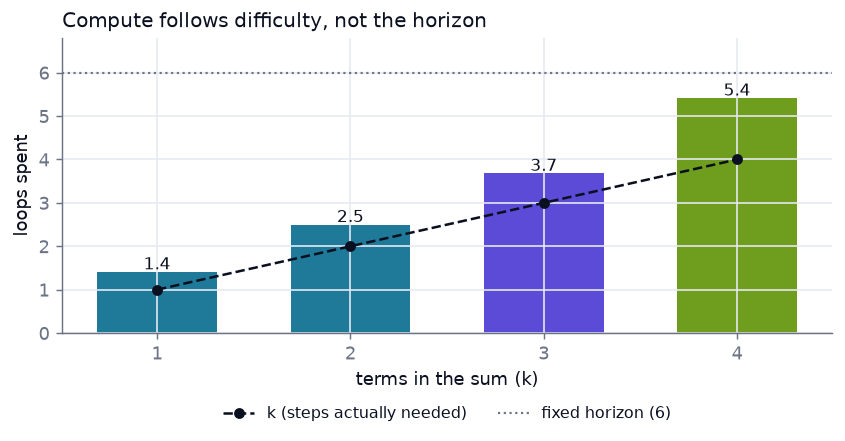

mean accuracy with halting    0.98 at 3.25 loops
mean accuracy at fixed T = 4  0.78 at 4.00 loops
mean accuracy at fixed T = 6  0.70 at 6.00 loops
halting vs T=4: 1.23x fewer loops, and it overshoots on k=4 instead of stopping at 4


In [9]:
class Halted(nn.Module):
    '''Frozen looped core + a halting head (ACT-style cumulative exit).'''
    def __init__(self, base):
        super().__init__()
        self.base, self.halt = base, nn.Linear(D, 1)
        for p in base.parameters():
            p.requires_grad_(False)

    def forward(self, a, loops=None):
        b, k = a.shape
        loops = self.base.loops if loops is None else loops
        x = self.base.embed(a) + self.base.pos(torch.arange(k))
        for blk in self.base.prelude:
            x = blk(x)
        e, h = x, torch.zeros_like(x)
        remaining = torch.ones(b)
        logits, probs, exits = [], [], []
        for t in range(loops):
            y = h + self.base.loop_index(torch.tensor(t))
            for blk in self.base.core:
                y = blk(y)
            h = self.base.A * h + self.base.B * e + y
            z = h
            for blk in self.base.coda:      # every pass is decoded, so every pass can answer
                z = blk(z)
            p = torch.sigmoid(self.halt(self.base.norm(h[:, -1]))).squeeze(-1)
            logits.append(self.base.head(self.base.norm(z[:, -1])))
            probs.append(p)
            exits.append(remaining * p)
            remaining = remaining * (1 - p)
        return logits, probs, exits


torch.manual_seed(0)
halted = Halted(looped)
opt = torch.optim.AdamW(halted.halt.parameters(), lr=1e-2)
for step in range(400):
    k = int(torch.randint(1, 5, (1,)))
    a, y = make_batch(64, k)
    logits, probs, exits = halted(a, loops=k + 2)
    # answer term: weighted by how likely this pass is the one we stop at
    answer_term = sum((exits[t] * F.cross_entropy(logits[t], y, reduction="none")).mean()
                      for t in range(len(logits)))
    # stop term: "by this pass the sum has been added k times, so stop here"
    ones = torch.ones(a.shape[0])
    stop_term = sum(F.binary_cross_entropy(probs[t], ones if t >= k else 1 - ones)
                    for t in range(len(logits))) / len(logits)
    loss = answer_term + 0.3 * stop_term
    opt.zero_grad(); loss.backward(); opt.step()


@torch.no_grad()
def spend(k, loops=6, threshold=0.5):
    '''Read the answer at the pass the model decides to exit at.'''
    a, y = make_batch(256, k)
    logits, probs, exits = halted(a, loops=loops)
    cdf = torch.stack(exits).cumsum(0)                        # P(exited by pass t)
    choice = (cdf < threshold).sum(0).clamp(max=loops - 1)     # first pass over threshold
    guesses = torch.stack([lg.argmax(-1) for lg in logits])[choice, torch.arange(a.shape[0])]
    return (guesses == y).float().mean().item(), (choice + 1).float().mean().item()

budget = {k: spend(k) for k in range(1, 5)}
for k, (acc, used) in budget.items():
    print(f"k={k}: accuracy {acc:.2f}, loops actually spent {used:.2f}")

fig, ax = plt.subplots(figsize=(6.6, 3.6))
ks = list(budget); used = [budget[k][1] for k in ks]
bars = ax.bar(ks, used, color=[CYAN, CYAN, VIOLET, LIME], width=0.62)
for b, v in zip(bars, used):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.06, f"{v:.1f}", ha="center", fontsize=9.5)
ax.plot(ks, ks, "o--", color=INK, linewidth=1.4, markersize=5, label="k (steps actually needed)")
ax.axhline(6, color=MUTED, linestyle=":", linewidth=1.2, label="fixed horizon (6)")
ax.set_xlabel("terms in the sum (k)"); ax.set_ylabel("loops spent")
ax.set_title("Compute follows difficulty, not the horizon", loc="left")
ax.set_ylim(0, 6.8); ax.set_xticks(ks)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8.6,
          frameon=False)
fig.tight_layout(); save(fig, "05-halting.png"); plt.show()
avg = sum(used) / len(used)
mean_acc = sum(budget[k][0] for k in budget) / len(budget)
fixed_acc = sum(accuracy(looped, k, 4) for k in range(1, 5)) / 4
print(f"mean accuracy with halting    {mean_acc:.2f} at {avg:.2f} loops")
print(f"mean accuracy at fixed T = 4  {fixed_acc:.2f} at 4.00 loops")
print(f"mean accuracy at fixed T = 6  {sum(accuracy(looped, k, 6) for k in range(1, 5)) / 4:.2f} at 6.00 loops")
print(f"halting vs T=4: {4 / avg:.2f}x fewer loops, and it overshoots on k=4 instead of stopping at 4")

柱子跟着 `k` 走而不是跟着预算走，而且准确率是在模型真正退出的那一次循环上读的——所以提前停
不吃亏。标定得准不准，数字自己会说：`k = 1…4` 分别花掉 1.4、2.5、3.7、5.4 次循环。它跟着难度
走，平均多花半次左右，但始终没顶到 6 的上限。对照第 2 节：同一组权重固定跑 `T = 6` 时比 `T = k` 更*差*；有了停机头，模型可以留下好的
那一次、把多余的丢掉。这就是自适应计算的全部意义。

三点要精确：

- 这个头是在冻结主干*之后*训练的，损失由两项组成：按"在此次循环退出"概率加权的交叉熵，以及一句
  "到这次循环为止答案已在状态里"的二分类。OpenMythos 只提供这个门（`ACTHalting`，
  `act_threshold = 0.99`，取代这里的 0.5 累积切点），本身没有停机损失；
- 0.5 是延迟/准确率的旋钮，不是定律。调高它就要多花循环；
- 停机救不了第 2 节的外推失败。如果答案不在状态里，晚点退出只是在错误答案上多花算力。

## 5. 同一件事，被工程化之后

上面所有代码大约 150 行。[OpenMythos](https://github.com/kyegomez/OpenMythos) 是同一个想法，
加上一次真实训练需要的东西：GQA/MLA attention、带共享专家的细粒度 MoE、逐次循环的 LoRA、ACT，
以及用正弦编码（加到前 `dim // 8` 个通道）实现的 loop index。

| 部件 | 我们的玩具 | OpenMythos | 它为什么存在 |
| --- | --- | --- | --- |
| 分块 | 1 prelude + 2 共享 + 1 coda | `prelude_layers=2`、`coda_layers=2`、共享 `RecurrentBlock` | 便宜的地方给深度，不便宜的地方给宽度 |
| 注入 | `h = A·h + B·e + y` | `LTIInjection`（`log_A`、`log_dt`、`B`） | 状态有界，且是保证的 |
| Loop index | 学习到的查表嵌入，加到全部通道 | `loop_index_embedding`：正弦，加到前 `dim // 8` 通道 | 块必须知道自己是第几步 |
| 逐次特化 | 无 / 可选 LoRA | 每次循环一个 `LoRAAdapter(rank=16)` | 几千个参数就买到特化 |
| 停机 | 冻结主干的 ACT 头（带停机损失） | `ACTHalting`，`act_threshold=0.99`，无停机损失 | 逐位置的退出判断 |
| 宽度 | 稠密 MLP | `MoEFFN`（64 专家、top-4、2 共享） | 跨领域的广度 |
| 注意力 | 4 头 MHA | GQA 或 MLA 可切换 | KV cache 的经济学 |

装上它，在笔记本能承受的尺寸下跑一次真的。

In [10]:
# pip install git+https://github.com/kyegomez/OpenMythos   (skip this cell if unavailable)
import warnings
warnings.filterwarnings("ignore", message=".*IProgress not found.*")

try:
    from open_mythos.main import MythosConfig, OpenMythos
    HAVE_MYTHOS = True
except Exception as exc:            # pragma: no cover - offline fallback
    HAVE_MYTHOS = False
    print("open-mythos not installed:", exc)

if HAVE_MYTHOS:
    cfg = MythosConfig(
        vocab_size=256, dim=128, n_heads=4, n_kv_heads=2, max_seq_len=32,
        max_loop_iters=8, prelude_layers=1, coda_layers=1, attn_type="gqa",
        n_experts=4, n_shared_experts=1, n_experts_per_tok=2, expert_dim=64,
        lora_rank=8, act_threshold=0.99,
    )
    mythos = OpenMythos(cfg).eval()
    tokens = torch.randint(0, cfg.vocab_size, (2, 12))
    print(f"OpenMythos tiny config: {sum(p.numel() for p in mythos.parameters()):,} params, "
          f"{cfg.max_loop_iters} max loops")
    with torch.no_grad():
        z = {}
        for loops in (1, 2, 4, 8):
            z[loops] = mythos(tokens, n_loops=loops)
            print(f"  n_loops={loops}: logits {tuple(z[loops].shape)}, "
                  f"mean |logit| {z[loops].abs().mean():.3f}")
        drift = (z[8] - z[1]).abs().max()
        print(f"  max |logit(8 loops) - logit(1 loop)| = {drift:.3f}")

OpenMythos tiny config: 462,274 params, 8 max loops
  n_loops=1: logits (2, 12, 256), mean |logit| 0.162
  n_loops=2: logits (2, 12, 256), mean |logit| 0.160
  n_loops=4: logits (2, 12, 256), mean |logit| 0.160
  n_loops=8: logits (2, 12, 256), mean |logit| 0.160
  max |logit(8 loops) - logit(1 loop)| = 0.063


同一份输入、四种算力预算、一组权重。API 本身就是那个旋钮：`n_loops` 是一次前向的参数，
于是服务成本按请求决定，而不是在架构阶段定死。

对上面数字要诚实：在随机初始化下，输出几乎不随 `n_loops` 变化——`max |Δlogit|` 大约是平均 `|logit|` 的五分之二
——而这恰好是对的：没训练过的循环块几乎没有东西可加，注入门让状态停在 `e` 附近。真正
有意思的是机制*允许*状态持续演化而不炸掉；等训练让块有东西可算，深度才会被花掉。

源码里值得按顺序看的地方：

1. `LTIInjection`（约 684 行）—— `get_A()` 和更新式。十行代码，是递归能活下来的原因。
2. `RecurrentBlock.forward`（约 825 行）—— 循环体：loop index、注入、逐次 LoRA、可选 ACT。
3. `ACTHalting`（约 750 行）—— 累积退出与逐位置的门。
4. `OpenMythos.__init__`（约 926 行）—— prelude / recurrent / coda 怎么接起来，包括共享权重的
   head。
5. `tests/small_benchmark.py` —— 在 `n_loops ∈ {1, 2, 4, 8, 16}` 上做深度扫描，并与同深度固定
   基线对比；也就是本 notebook 在玩具尺度上跑的那个实验（它真的会训练）。

你可能会看到被引用的参数效率结论——循环模型能追平大约两倍于它的固定深度模型——它来自这套实现所
依据的 Parcae scaling law（Parcae 就在目录里），而不是来自这份 notebook。我们的玩具是教学装置：
把数字当形状看，别当量级看。

## 6. 接下来读什么

到这里，机制上的图景你已经有了。文献真正难的地方有三处：**注入什么、注入到哪**（架构），
**每个 token 该花多少算力**（自适应计算），以及**怎么服务一个深度是变量的模型**（系统）。

- **[自适应计算](https://github.com/Mrkkew/Awesome-Loop-Transformers#adaptive-compute)**
  —— 深度组合、固定视界的潜在推理、late entry、停机。如果 §2 和 §4 是你觉得有意思
  的部分，从这里开始。
- **架构与扩展** —— 稳定性、looped MoE、latent lattice、model carving。如果 §3 打动你，从这里开始。
- **系统与应用** —— 面向循环的投机解码、循环下的 KV cache 增长、循环内补全式草稿。如果你关心
  服务的账单，从这里开始。
- **基础与理论** —— 复用何时有效、不动点、为什么深度并不均质。想要证明的话，从这里开始。

目录收录约 280 篇论文、九个主题，每篇都有原创的中英文概述，有官方代码的地方都给了链接。如果这份
notebook 改变了你读其中某一篇的方式，它就完成任务了。

*修改 `tutorials/build_notebooks.py` 里的正文之后重新生成：
`python tutorials/build_notebooks.py --execute`。*